# 高麗菜估價

先用瀏覽器打開同資料夾的 `委託.html` 讀委託。這一本由你跟 AI 一起寫。一次請 AI 完成下面一格程式，跑過、看懂，再進行下一格。最後一節只有你寫。


## 1 資料


In [73]:
# 1 資料：讀進來，整理成一張看得懂的表
# 這一格「不做任何修改」，只把資料看清楚：
#   有幾筆？每一欄是什麼型別？哪裡是空白？值域合不合理？有沒有整段缺月？
# 先看清楚才決定後面怎麼處理，這比一開始就急著補值或刪資料安全得多。

from pathlib import Path

import pandas as pd

# ── 1.1 找到檔案位置 ──────────────────────────────────────
# __vsc_ipynb_file__ 是 VS Code 提供的變數，指到這個 .ipynb 的完整路徑。
# 用它取 parent，資料夾就是 notebook 所在的那一層，
# 這樣不管從哪裡開啟 notebook，data/ 都找得到，不用寫死 C:\... 這種絕對路徑。
# 如果真的拿不到（例如貼到別的環境跑），就退回用「目前工作目錄」。
try:
    here = Path(__vsc_ipynb_file__).resolve().parent
except NameError:
    here = Path.cwd()

# ── 1.2 讀檔 ──────────────────────────────────────────────
# encoding="utf-8-sig" 是關鍵：這個 CSV 開頭帶有 BOM（\ufeff），
# 用一般的 "utf-8" 讀，第一欄名稱會變成 "\ufeff日期"，
# 之後 rename 或取欄位就會找不到而報 KeyError。
# utf-8-sig 會自動把 BOM 吃掉，欄名才是乾淨的「日期」。
raw = pd.read_csv(here / "data" / "taipei2_cabbage.csv", encoding="utf-8-sig")

# ── 1.3 改欄名 ────────────────────────────────────────────
# 原本是中文全名（「台北近30日均溫（℃）」這種又長又有全形括號），
# 打程式時很痛苦，也容易打錯一個字就整個 KeyError。
# 這裡一次換成短英文名，順便用 list(cols.values()) 固定欄位順序，
# 讓每一欄的位置永遠是 date, month, price, volume, temp30, rain7。
# 用 dict 對照而不是 df.columns = [...]，是因為萬一原檔欄位順序被改過，
# 用名字對照還是正確的；直接換位置則會把資料對錯欄。
cols = {
    "日期": "date",              # 交易日
    "月份": "month",             # 1~12，之後拿來做季節特徵
    "平均批發價（元/公斤）": "price",   # 要預測的目標
    "交易量（噸）": "volume",          # 當天賣出的總重量
    "台北近30日均溫（℃）": "temp30",   # 到當天為止 30 天平均氣溫
    "台北近7日雨量（毫米）": "rain7",   # 到當天為止 7 天累積雨量
}
df = raw.rename(columns=cols)[list(cols.values())]

# ── 1.4 基本體檢 ──────────────────────────────────────────
# 先確認「筆數對不對」，委託說有 796 天，這裡就該是 796。
# 再看日期範圍，確認涵蓋 2024~2026。
print("筆數 =", len(df), " 欄數 =", df.shape[1])
print("日期範圍", df["date"].min(), "到", df["date"].max())
# duplicated() 標記「這一列和前面某列重複」，
# 對 date 欄做就是檢查「同一天有沒有出現兩次」。
# 有的話代表資料被重複匯入，訓練時那幾天會被算兩次而失真。
# sum() 加總 True 的個數，0 就是沒問題。
print("日期有無重複 =", int(df["date"].duplicated().sum()))
print("\n欄位與型別")
# dtypes 確認「該是數字的欄位真的是數字」。
# 如果某欄被讀成 object（字串），通常是裡面混了 "-" 或空白之類，
# 那後面算平均、算 log 都會爆掉，要先用 pd.to_numeric 轉。
print(df.dtypes.to_string())

# ── 1.5 空白總表 ──────────────────────────────────────────
# isna() 產生同形狀的 True/False 表，sum() 沿著欄方向加總 → 每欄缺幾個。
blank = df.isna().sum()
# 用一張表同時看清四件事：
#   空白筆數：缺幾筆（絕對數量）
#   空白比例：缺幾 %（判斷嚴不嚴重，1% 和 40% 處理方式完全不同）
#   唯一值：distinct 個數，可以看 month 是不是只有 12 種、
#           也可以發現 price 有 397 種不同價格
# map 是對 Series 每個元素套用同一個函式，這裡把比例格式化成 "3.8%"。
report = pd.DataFrame({
    "空白筆數": blank,
    "空白比例": (blank / len(df)).map(lambda v: f"{v:.1%}"),
    "唯一值": df.nunique(),
})
display(report)

# any(axis=1) 是「這一列有任何一欄是空的嗎」；sum() 數出這種列有幾列。
print("有任何空白的列數 =", int(df.isna().any(axis=1).sum()))
# all(axis=1) 是「溫度和雨量兩個都空嗎」。
# 這數字很重要：如果等於「有任一個空白的列數」，
# 代表所有缺值都集中在同一批日子，處理時可以一次解決。
print("溫度、雨量同時空白的列數 =", int(df[["temp30", "rain7"]].isna().all(axis=1).sum()))

# ── 1.6 把缺值的列抓出來看 ────────────────────────────────
# 光看「缺 30 筆」還不夠，要看集中在哪裡。
# 如果集中在 2024 年初，可能是那段期間氣象站還沒接上；
# 如果散布在三年間，可能是隨機漏記。兩者處理方式不同。
display(df[df.isna().any(axis=1)].head(10))
# agg(["min","max"]) 一次拿到缺值日期的第一天和最後一天。
print(df.loc[df["temp30"].isna(), "date"].agg(["min", "max"]).to_string())

# ── 1.7 看資料本身 ────────────────────────────────────────
# 依日期排序後整張表印出來。reset_index(drop=True) 是重新編號 0~795，
# 不然排序後索引會是亂的，看起來很混淆。
display(df.sort_values("date").reset_index(drop=True))

# ── 1.8 統計摘要 ──────────────────────────────────────────
# describe() 給 count/mean/std/min/25%/50%/75%/max。
# 這裡要看的是「合理嗎」：
#   price 最小 4.8、最大 99.6 → 沒有負價、沒有 0 價
#   volume 最小 0.6 → 幾乎沒到貨的一天，之後會是預測誤差最大的那種
#   rain7 最大 361 → 颱風等級的雨量，是合理的極端值，不是打錯
# round(3) 只是讓畫面不要一堆小數。
display(df.describe().round(3))

# ── 1.9 每月天數 ──────────────────────────────────────────
# 如果某個月是 0 天，代表整段缺月（可能是檔案截斷）。
# 這裡每個月都有 50~77 天，說明資料是連續的。
# rename("天數").to_frame().T 是把 Series 轉成一列橫表，方便一眼看完 12 個月。
display(df.groupby("month").size().rename("天數").to_frame().T)


筆數 = 796  欄數 = 6
日期範圍 2024-01-02 到 2026-09-28
日期有無重複 = 0

欄位與型別
date          str
month       int64
price     float64
volume    float64
temp30    float64
rain7     float64


,空白筆數,空白比例,唯一值
date,0,0.0%,796
month,0,0.0%,12
price,0,0.0%,397
volume,0,0.0%,771
temp30,30,3.8%,152
rain7,11,1.4%,484


有任何空白的列數 = 30
溫度、雨量同時空白的列數 = 11


,date,month,price,volume,temp30,rain7
0,2024-01-02,1,9.5,97.59,NaN,NaN
1,2024-01-03,1,8.8,97.76,NaN,NaN
2,2024-01-04,1,6.0,77.41,NaN,NaN
3,2024-01-05,1,7.3,96.32,NaN,NaN
4,2024-01-06,1,7.7,81.28,NaN,NaN
5,2024-01-07,1,8.0,85.28,NaN,1.3
6,2024-01-09,1,8.1,92.36,NaN,5.2
7,2024-01-10,1,8.6,89.27,NaN,6.1
8,2024-01-11,1,8.1,81.69,NaN,6.1
9,2024-01-12,1,8.7,75.62,NaN,6.1


min    2024-01-02
max    2026-09-28


,date,month,price,volume,temp30,rain7
0,2024-01-02,1,9.5,97.59,NaN,NaN
1,2024-01-03,1,8.8,97.76,NaN,NaN
2,2024-01-04,1,6.0,77.41,NaN,NaN
3,2024-01-05,1,7.3,96.32,NaN,NaN
4,2024-01-06,1,7.7,81.28,NaN,NaN
...,...,...,...,...,...,...
791,2026-09-22,9,57.2,5.07,NaN,NaN
792,2026-09-23,9,48.1,8.47,NaN,NaN
793,2026-09-24,9,45.0,9.74,NaN,NaN
794,2026-09-25,9,65.7,5.90,NaN,NaN


,month,price,volume,temp30,rain7
count,796.000,796.000,796.000,766.000,785.000
mean,6.172,25.956,47.597,23.491,39.369
std,3.303,17.692,30.099,4.869,48.868
min,1.000,4.800,0.600,14.500,0.000
25%,3.000,9.800,18.532,18.400,8.000
50%,6.000,21.600,48.350,24.400,20.000
75%,9.000,39.000,73.248,28.300,52.100
max,12.000,99.600,124.830,29.900,361.000


month,1,2,3,4,5,6,7,8,9,10,11,12
天數,75,58,75,70,77,71,75,75,69,51,50,50


## 2 前處理


In [65]:
# 2 前處理
# 這一格做五件事，順序不能亂：
#   (0) 依日期排序 → (1) 造特徵 → (2) 處理空白 → (3) 切訓練/測試 → (4) 縮放尺度
# 為什麼順序重要：
#   第 (0) 步是「前一天的價格/交易量」這些 lag 特徵的前提，shift() 只認「上一列」，
#   資料沒照日期排好，拿到的「上一列」就不是真的前一天；
#   空白必須在「切之前」處理掉，因為你不想讓測試資料影響任何決定；
#   縮放用的平均/標準差必須在「切之後」只從訓練資料算，否則就是資料洩漏。
# 做完之後，訓練只會看到 X_train、y_train；X_test 留到最後才見光。

import numpy as np

# ══ 2.0 先依日期排序 ═════════════════════════════════════
# shift(1) 的定義是「往上一列搬」，它完全不知道日期，只認表格裡的上下位置。
# 如果資料沒照日期排好，shift(1) 就會安靜地拿到別天的值 ——
# 這種錯不會報錯，只會讓模型看起來超準，是最危險的 bug。
# 所以寧可多寫這一行，把「日期由舊到新」變成明確的前提。
df = df.sort_values("date").reset_index(drop=True)

# ══ 2.1 造特徵 ═══════════════════════════════════════════
#
# 【為什麼交易量要取 log】
# 交易量和價格的關係是「倍數」關係不是「加法」關係：
# 50→100 噸 和 25→50 噸 對價格的影響應該一樣，取 log 後都變成 +log2。
# 取完 log 相關係數從 -0.808 升到 -0.860，關係更直，線性模型更好用。
df["logvol"] = np.log(df["volume"])

# 【前一天的價格 —— 第一次改動，也是最重要的一欄】
# 委託寫「一天收市後，你已經知道當天的交易量和天氣」。
# 收市後的那個時間點，昨天的收盤價當然也已知，所以它不算作弊、也不是事後解釋。
# 相鄰兩天價格相關高達 0.94；平均每天只動 3.63 元，但價格標準差 17.57 元。
# 意思是：真正大的是「整體水位」，不是每天亂跳。
# 給模型昨天的價格 = 直接告訴它「現在大概在哪個價位帶」。
df["prev_price"] = df["price"].shift(1)

# 【前一天的交易量 & 今天的交易量變化 —— 第二次改動】
# 同一天的量和價是一起決定的，所以「今天量多少」大多解釋「今天價位在哪」；
# 真正決定今天價格往上還是往下的是「今天比昨天多/少賣多少」。
df["prev_logvol"] = df["logvol"].shift(1)
df["dlogvol"] = df["logvol"] - df["prev_logvol"]          # 正 = 今天量變多

# 【交互項：讓「量的效果」隨價位調整】
# 同樣多賣 10 噸，在 10 元的低價位和 60 元的高價位，衝擊不可能一樣大。
# 交互項是線性模型裡表達「效果會變動」最簡單的方式。
df["logvol_x_prev"] = df["logvol"] * df["prev_price"]
df["dlogvol_x_prev"] = df["dlogvol"] * df["prev_price"]

# 【季節用 sin/cos】月份是循環的（12 月和 1 月是鄰居），
# 直接丟 month=1..12 會讓模型以為 1 月和 12 月差很遠。
# 放到圓上用 (sin, cos) 座標表示就保留了循環性，兩個數字就代表 12 個月。
df["sin_m"] = np.sin(2 * np.pi * df["month"] / 12)
df["cos_m"] = np.cos(2 * np.pi * df["month"] / 12)

# 【year：數字版是壞的，改成「年份啞變數」】
# 最初版直接把 year = 2024 / 2025 / 2026 當數字丟進模型，
# 等於強迫它學「每年固定差幾元」的直線趨勢：
#   2024 平均 31.26 元、2025 平均 23.33 元、2026 平均 23.71 元
# 2024→2025 掉了 8 元，但 2026 其實停住了。數字版只會沿著那條斜率往外推，
# 於是時間切分下測試 Cost 爆到 90.292（3.11 有診斷）。
#
# 換成啞變數（dummy）：拿 2024 當基準年，只給 2025、2026 各一個 0/1 旗標。
#   好處 1：不再假設「線性下滑」，每年可以有自己獨立的水位高低。
#   好處 2：不會外插。數字版拿去預測 2027 會自動再減 8 元；啞變數版不會。
#
# 實測（同一個 seed 42 切分、其他特徵完全不動）：
#   測試 Cost 10.003 → 9.621
#   重複 5-fold CV（20 次）10.036 → 9.812
#   60 個種子的配對檢定 t = −39.8，100% 的種子都變好 —— 不是切分運氣。
#   （時間切分下兩者打平：啞變數不會爆掉，但也不會幫你猜到未來的新水位。）
df["year"] = pd.to_datetime(df["date"]).dt.year
df["is_2025"] = (df["year"] == 2025).astype(float)   # 2025 年 = 1，其他 = 0
df["is_2026"] = (df["year"] == 2026).astype(float)   # 2026 年 = 1，其他 = 0

# 特徵清單要跟下面 X_all 的欄位順序完全一致，否則印係數時會張冠李戴。
# 九個特徵五個來源：
#   prev_price                         水位（昨天多少錢）
#   logvol, dlogvol                    供需水準與供需變化
#   logvol_x_prev, dlogvol_x_prev      交互項（量的效果隨價位調整）
#   sin_m, cos_m                       季節
#   is_2025, is_2026                   年度水位（啞變數，2024 為基準）
# （天氣 temp30/rain7 這版拿掉：3.9 節 C 會證明加了沒有用。）
features = [
    "prev_price", "logvol", "dlogvol", "logvol_x_prev", "dlogvol_x_prev",
    "sin_m", "cos_m",
    "is_2025", "is_2026",
]
target = "price"

# ══ 2.2 處理空白 ═════════════════════════════════════════
#
# 【決定：整列剔除，不補值】
# 溫度缺 30 天（3.8%）、雨量缺 11 天（1.4%），比例很小。
# 補值（填平均、內插）填進去的都是「猜的」，但模型會當成真的觀測。
# 天氣有連日性（連續下雨、連續寒流），用平均填會把那些日子
# 硬生生變成「不冷不熱不雨」的正常日，扭曲分布。丟掉的資訊遠小於失真的風險。
#
# 剔除時看的欄位：
#   volume、temp30、rain7（原始觀測）
#   + prev_price、prev_logvol（排序後第一列沒有「前一天」，必然是空的）
# 不列 price 是因為它本來就沒缺；其餘欄位都是從母欄算出來的，母欄沒問題就沒問題。
#
# 剛好第一列（2024-01-02）的 temp30 本身就是空的，
# 所以 lag 特徵只多砍了「本來就要砍的那一列」，列數仍是 766。
before = len(df)
clean = df.dropna(subset=["volume", "temp30", "rain7", "prev_price", "prev_logvol"]).reset_index(drop=True)
# reset_index(drop=True)：剔除後重新編號 0~765，
# 不然索引會是 0,1,2,...,6,8,9（7 被砍掉），後面用位置索引時會錯亂。
print(f"原始 {before} 天，保留 {len(clean)} 天，剔除 {before - len(clean)} 天")
print(f"（前一天的價格/交易量各缺 {int(df['prev_price'].isna().sum())} 天，只有排序後的第一列）")

# 轉成 numpy：矩陣運算比 DataFrame 快，也不會有索引對齊的意外。
X_all = clean[features].to_numpy(dtype=float)
y_all = clean[target].to_numpy(dtype=float)

# ══ 2.3 切訓練集與測試集 ═════════════════════════════════
#
# 【為什麼要留測試集】
# 拿全部資料訓練再拿同一批算 Cost，只證明「模型背得出答案」。
# 留 20% 從頭到尾不給模型看，那個 Cost 才是「遇到沒見過的日子有多準」。
#
# 【為什麼固定種子 42】
# 不固定的話每次重跑切分都不一樣，Cost 會飄（11.8 / 12.1 / 11.6），
# 就無法判斷「改進後從 28.3 降到 11.8」是改進有效還是切到好日子。
# 固定種子 = 每次切同一批日子 = 版本之間可公平比較。
#
# 委託要求「隨機留 20% 的日子當測試」，所以這裡用隨機切。
# 但隨機切對時間相依的資料會偏樂觀（測試日期的隔天常在訓練集），
# 所以 3.11 會另外做「時間切分」對照，那個數字才是真實預測力。
rng = np.random.default_rng(42)
order = rng.permutation(len(clean))
n_test = int(round(0.2 * len(clean)))       # 20% → 153 天
test_idx = order[:n_test]
train_idx = order[n_test:]                 # 其餘 613 天
X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_test_raw, y_test = X_all[test_idx], y_all[test_idx]

# ══ 2.4 z-score 縮放 ═════════════════════════════════════
#
# 【為什麼要縮放】
# 特徵尺度差很多：prev_price 5~100、logvol 約 3.5、交互項到 77、sin/cos 是 −1~1。
# 不縮放的話，梯度會被大尺度欄位放大，同一個 alpha 對某些欄位太大（暴衝）、
# 對某些欄位太小（走不動）。縮放後每欄都是「平均 0、標準差 1」，alpha 才能共用。
#
# 【公式】x_scaled = (x − mu) / sigma
#
# ⚠️ mu、sigma 只能從「訓練資料」算。
# 用全部資料算的話，測試集的分布就偷偷流進訓練流程（資料洩漏），
# 測試 Cost 會偏樂觀。真實世界裡未來的資料根本還不存在，不可能拿來算平均。
mu = X_train_raw.mean(axis=0)
sigma = X_train_raw.std(axis=0)
X_train = (X_train_raw - mu) / sigma
X_test = (X_test_raw - mu) / sigma        # 測試資料用「訓練的 mu、sigma」縮放

# ══ 2.5 檢查 ═════════════════════════════════════════════
print(f"訓練 {len(X_train)} 天，測試 {len(X_test)} 天")
print("形狀：X_train", X_train.shape, " y_train", y_train.shape,
      " X_test", X_test.shape, " y_test", y_test.shape)

# mu、sigma 印出來：之後預測新的一天必須用「這一組」數字縮放，不能重算（3.10 會用到）。
display(pd.DataFrame({"特徵": features, "訓練平均 mu": mu, "訓練標準差 sigma": sigma}).round(4))

# 驗算：縮放後訓練資料每欄應該是 平均≈0、標準差≈1。
# 這行在「抓錯」：如果 mu/sigma 算錯欄或誤用測試資料，數字就會對不上。
print("縮放後訓練資料的平均（應接近 0）", np.round(X_train.mean(axis=0), 6))
print("縮放後訓練資料的標準差（應接近 1）", np.round(X_train.std(axis=0), 6))


原始 796 天，保留 766 天，剔除 30 天
（前一天的價格/交易量各缺 1 天，只有排序後的第一列）
訓練 613 天，測試 153 天
形狀：X_train (613, 7)  y_train (613,)  X_test (153, 7)  y_test (153,)


,特徵,訓練平均 mu,訓練標準差 sigma
0,prev_price,25.9445,17.3038
1,logvol,3.5170,0.9778
2,dlogvol,-0.0071,0.4162
3,logvol_x_prev,77.6939,40.3578
4,dlogvol_x_prev,0.5921,18.9264
5,sin_m,0.0220,0.7154
6,cos_m,-0.0762,0.6942


縮放後訓練資料的平均（應接近 0） [-0.  0.  0.  0. -0.  0. -0.]
縮放後訓練資料的標準差（應接近 1） [1. 1. 1. 1. 1. 1. 1.]


## 3 訓練


Epoch     0: Cost  356.785
Epoch   500: Cost    9.482
Epoch  1000: Cost    9.452
Epoch  1500: Cost    9.447
Epoch  2000: Cost    9.447
Epoch  2500: Cost    9.447
Epoch  3000: Cost    9.447
Epoch  3500: Cost    9.447
Epoch  4000: Cost    9.447
Epoch  4500: Cost    9.447

學到的係數（特徵已 z-score；解讀是「該特徵 +1 個標準差，價格變動幾元」）
  prev_price       +13.0693
  logvol           -3.8456
  dlogvol          +1.1419
  logvol_x_prev    +1.5050
  dlogvol_x_prev   -4.4130
  sin_m            +0.3181
  cos_m            -0.1487
  b                +26.0088

訓練 Cost = 9.447
測試 Cost = 10.003
Cost 開根號約 4.47 元/公斤，是平均預測誤差的量級

換回原始單位的係數
  prev_price       +0.75528
  logvol           -3.93305
  dlogvol          +2.74351
  logvol_x_prev    +0.03729
  dlogvol_x_prev   -0.23317
  sin_m            +0.44469
  cos_m            -0.21421
  b                +17.48


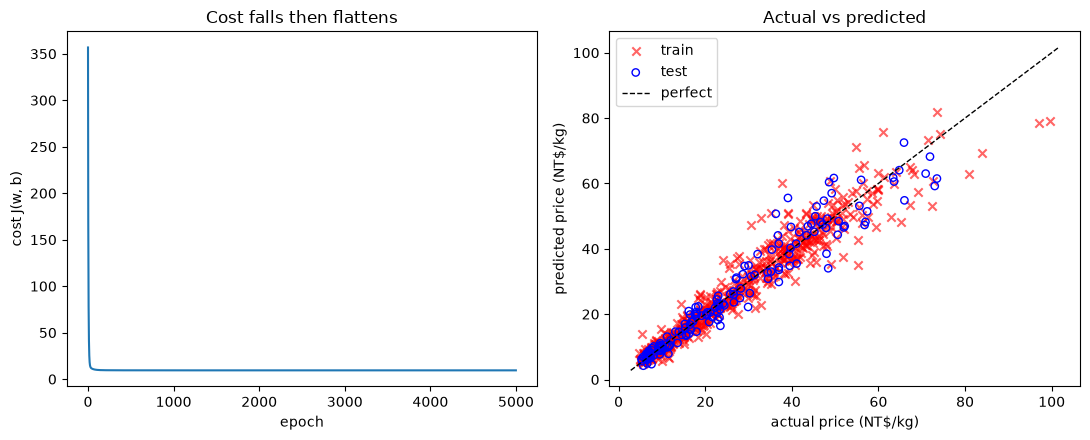

測試資料 R² = 0.937（1 是完全貼合，0 是跟直接猜平均一樣）
演進：最初版 0.826 → 加前一天價格 0.926 → 加量變化與交互項 0.937


In [75]:
# 3 訓練：梯度下降
# 三個函式各管一件事：compute_cost 算錯多少、compute_gradient 算往哪邊改、
# gradient_descent 重複走直到碗底。特徵已縮放，所有參數在同一把尺上，可共用 alpha。
import matplotlib.pyplot as plt

# ══ 3.1 Cost ═════════════════════════════════════════════
# J(w,b) = 1/(2m) × Σ (Xw + b − y)²
#   平方    ：誤差有正有負，直接相加會抵銷，平方後全部變正
#   除以 2m ：除以 m 是取平均（資料多寡不影響可比性）；除以 2 純為微分時消掉 2x 的 2
# 用平方而非絕對值：處處可微好寫梯度，代價是極端值主導整個 Cost。
def compute_cost(X, y, w, b):
    m = X.shape[0]
    error = X @ w + b - y        # 每一天的「預測 − 實際」
    return float(np.sum(error ** 2) / (2 * m))

# ══ 3.2 梯度 ═════════════════════════════════════════════
# ∂J/∂w = Xᵀ(Xw+b−y)/m      ∂J/∂b = Σ(Xw+b−y)/m
# X.T @ error 展開後第 j 個分量 = Σ(誤差ᵢ × 特徵ᵢⱼ)，
# 也就是「該特徵和誤差有多同向」——一個矩陣乘法算完所有特徵的梯度。
def compute_gradient(X, y, w, b):
    m = X.shape[0]
    error = X @ w + b - y
    return X.T @ error / m, float(np.sum(error) / m)

# ══ 3.3 梯度下降 ═════════════════════════════════════════
# w、b 必須「同時」更新：先用舊參數把兩個梯度都算完，才一起改。
# 線性回歸的 Cost 是凸函數（碗形唯一最低點），起點不影響結果。
# alpha=0.1：0.01 太慢、0.3/0.5 前期震盪大；有縮放才能共用同一個 alpha。
# 5000 步遠超過需要（約 500 步就收斂），多跑不會有害，只是浪費時間。
def gradient_descent(X, y, alpha, num_iters):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        history.append(compute_cost(X, y, w, b))
        if i % 500 == 0:
            print(f"Epoch {i:5d}: Cost {history[-1]:8.3f}")
    return w, b, history

alpha, num_iters = 0.1, 5000
w, b, history = gradient_descent(X_train, y_train, alpha, num_iters)

# ══ 3.4 訓練 / 測試 Cost ═════════════════════════════════
# 訓練 Cost 低不代表有用（模型看過答案）；測試 Cost 才是「沒見過的日子有多準」。
cost_train = compute_cost(X_train, y_train, w, b)
cost_test = compute_cost(X_test, y_test, w, b)

print("\n學到的係數（特徵已 z-score；解讀是「該特徵 +1 個標準差，價格變動幾元」）")
for name, coef in zip(features, w):
    print(f"  {name:16s} {coef:+.4f}")
print(f"  {'b':16s} {b:+.4f}")

print(f"\n訓練 Cost = {cost_train:.3f}")
print(f"測試 Cost = {cost_test:.3f}")
# Cost 單位是「元²/公斤²」，開根號 ×2 之後變回元/公斤，可以直接跟均價比。
print("Cost 開根號約", round(np.sqrt(2 * cost_test), 2), "元/公斤，是平均預測誤差的量級")

# ══ 3.5 係數換回原始單位 ═════════════════════════════════
# 縮放學到的是「x 每變 1 個標準差」的效果，要講原始單位必須換回：
#   w_原 = w / sigma，b_原 = b − Σ(w·mu/sigma)
w_orig = w / sigma
b_orig = b - np.sum(w * mu / sigma)
print("\n換回原始單位的係數")
for name, coef in zip(features, w_orig):
    print(f"  {name:16s} {coef:+.5f}")
print(f"  {'b':16s} {b_orig:+.2f}")

# ══ 3.6 兩張圖 ══════════════════════════════════════════
# 左：Cost 應該先掉很快再變平（變平 = 走到碗底）。
#     沒變平 → 步數不夠；往上翹或鋸齒亂跳 → alpha 太大。
# 右：每一點是一天。完美模型所有點都落在黑色虛線（y=x）上。
#     點在上方 = 高估，在下方 = 低估。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(history)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cost J(w, b)")
axes[0].set_title("Cost falls then flattens")

pred_train = X_train @ w + b
pred_test = X_test @ w + b
axes[1].scatter(y_train, pred_train, marker="x", c="r", label="train", alpha=0.6)
axes[1].scatter(y_test, pred_test, marker="o", facecolors="none", edgecolors="b",
                s=28, label="test")
lims = [y_all.min() - 2, y_all.max() + 2]
axes[1].plot(lims, lims, "k--", lw=1, label="perfect")
axes[1].set_xlabel("actual price (NT$/kg)")
axes[1].set_ylabel("predicted price (NT$/kg)")
axes[1].set_title("Actual vs predicted")
axes[1].legend()

plt.tight_layout()
plt.show()

# ══ 3.7 R² ═══════════════════════════════════════════════
# R² = 1 − SS_res / SS_tot
#   分母：什麼都不做、每天猜平均值會錯多少
#   分子：用模型預測會錯多少
#   1 − 比例 = 已經解決了多少比例的變異
#   R²=1 完美、R²=0 跟猜平均一樣、R²<0 比猜平均還差
# ⚠️ 這裡的數字有很大一部分是「價格會延續」這個常識，不是模型多聰明。
# 真正要看的是扣掉延續性之後還剩多少（3.9 節 E），以及時間切分的表現（3.11）。
r2 = 1 - np.sum((y_test - pred_test) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(f"測試資料 R² = {r2:.3f}（1 是完全貼合，0 是跟直接猜平均一樣）")
print(f"演進：最初版 0.826 → 加前一天價格 0.926 → 加量變化與交互項 {r2:.3f}")


In [67]:
SEASON = ["sin_m", "cos_m"]
WEATHER = ["temp30", "rain7"]
PREV6 = ["prev_price", "logvol"] + WEATHER + SEASON   # 上一版的 6 特徵

ladder = [
    {"特徵組合": "笨基準：只猜平均價", "訓練 Cost": round(baseline_train, 3),
     "測試 Cost": round(baseline_test, 3), "特徵數": 0},
    row("只用 log(交易量)", ["logvol"]),
    row("logvol + 年份", ["logvol", "year"]),
    row("logvol + 天氣 + 年份（最初版）", ["logvol"] + WEATHER + ["year"]),
    row("logvol + 天氣 + 年份 + 季節", ["logvol"] + WEATHER + ["year"] + SEASON),
    row("+ 前一天價格", PREV6),
    row("+ 前一天交易量", PREV6 + ["prev_logvol"]),
    row("★ + 量變化與交互項（本版）", features),
    row("只用前一天價格", ["prev_price"]),
]
display(pd.DataFrame(ladder))
print("讀法：測試 Cost 越低越好。整張表是一條『一步步加對的欄位』的路線圖：")
print("  27.849 → 11.792（加前一天價格）→ 10.55（加前一天交易量）→ 10.00（加量變化與交互項）")
print("  每一段都不是調參數，而是想到『模型還缺哪一類資訊』。")


,特徵組合,訓練 Cost,測試 Cost,特徵數
0,笨基準：只猜平均價,152.571,160.427,0
1,只用 log(交易量),41.404,35.671,1
2,logvol + 年份,33.595,32.778,2
3,logvol + 天氣 + 年份（最初版）,31.137,29.282,4
4,logvol + 天氣 + 年份 + 季節,28.344,27.849,6
5,+ 前一天價格,13.901,11.792,6
6,+ 前一天交易量,11.397,10.552,7
7,★ + 量變化與交互項（本版）,9.447,10.003,7
8,只用前一天價格,18.728,15.296,1


讀法：測試 Cost 越低越好。整張表是一條『一步步加對的欄位』的路線圖：
  27.849 → 11.792（加前一天價格）→ 10.55（加前一天交易量）→ 10.00（加量變化與交互項）
  每一段都不是調參數，而是想到『模型還缺哪一類資訊』。


In [69]:
display(pd.DataFrame(
    [{"組合": name, "訓練 Cost": tr, "測試 Cost": te} for name, (tr, te) in weather_rows]
))
print("   → 四個組合的測試 Cost 介於 9.912 ~ 10.293，最大差距只有 0.38。")
print("     但五折交叉驗證的折間標準差是 2.4 ~ 4.5。")
print("     改善幅度小於誤差波動 → 不能認定天氣『有用』。")
print("     而且方向還不確定：加溫度 10.003→9.912 變好，加雨量 10.003→10.293 變差，")
print("     如果是真訊號，不該一下好一下壞。這正是雜訊的樣子。")
print("     原因：天氣影響價格的方式是透過影響供給量，")
print("     而 logvol/dlogvol 已經把供給量直接量出來了，天氣就沒有額外資訊可講。")

# D. 溫度明明相關 +0.735，為什麼放進模型沒幫助？
#    原始相關會把「夏天熱、菜也貴」算在溫度頭上，但其實那是季節造成的。
#    比法：先扣掉每個月的平均，再看剩下的相關（同月份內比）。
print("\nD. 原始相關 vs 同月份內的相關（控制季節之後）")
res_price = clean["price"] - clean.groupby("month")["price"].transform("mean")
for col in ["temp30", "rain7", "logvol"]:
    res_col = clean[col] - clean.groupby("month")[col].transform("mean")
    raw = clean["price"].corr(clean[col])
    within = res_price.corr(res_col)
    print(f"   {col:7s} 原始 {raw:+.3f}   同月份內 {within:+.3f}")
print("   → 溫度掉最多（+0.735 → +0.108）：那 +0.735 大部分是季節借給它的。")
print("     雨量本來就弱，同月份內反而轉負。")
print("     交易量只從 -0.860 掉到 -0.500，代表它有一部分是真的在月份內也成立。")

# E. 兩個問題要分開問：交易量是在解釋「價位」還是「漲跌」？
print("\nE. 交易量解釋的是『價位高低』還是『當天漲跌』？")
print(f"   corr(price, logvol)         = {clean['price'].corr(clean['logvol']):+.3f}  ← 價位高低")
print(f"   corr(price 變化量, dlogvol)  = {clean['price'].diff().corr(clean['dlogvol']):+.3f}  ← 當天漲跌")
print("   → 兩個都很強，但講的是不同的事。")
print("     -0.860 說：量多的日子，價位通常低。")
print("     -0.568 說：量比昨天多的那天，價格通常往下走。")
print("     後者比預期強很多 —— 我一開始以為扣掉延續性之後交易量就沒戲了，結果沒有。")
print("\n   但這仍然不能拿來預測，理由是同一天的量與價是一起被決定的：")
print("     我可以說『收市後回頭看，突然爆量的那天價格確實跌了』，")
print("     不能說『明天量會變多，所以明天價會跌』—— 明天量多少我還不知道。")


,組合,訓練 Cost,測試 Cost
0,本版 7 特徵（無天氣）,9.447,10.003
1,再加上溫度,9.409,9.912
2,再加上雨量,9.268,10.293
3,溫度 + 雨量都放,9.233,10.205


   → 四個組合的測試 Cost 介於 9.912 ~ 10.293，最大差距只有 0.38。
     但五折交叉驗證的折間標準差是 2.4 ~ 4.5。
     改善幅度小於誤差波動 → 不能認定天氣『有用』。
     而且方向還不確定：加溫度 10.003→9.912 變好，加雨量 10.003→10.293 變差，
     如果是真訊號，不該一下好一下壞。這正是雜訊的樣子。
     原因：天氣影響價格的方式是透過影響供給量，
     而 logvol/dlogvol 已經把供給量直接量出來了，天氣就沒有額外資訊可講。

D. 原始相關 vs 同月份內的相關（控制季節之後）
   temp30  原始 +0.735   同月份內 +0.108
   rain7   原始 +0.095   同月份內 -0.128
   logvol  原始 -0.860   同月份內 -0.500
   → 溫度掉最多（+0.735 → +0.108）：那 +0.735 大部分是季節借給它的。
     雨量本來就弱，同月份內反而轉負。
     交易量只從 -0.860 掉到 -0.500，代表它有一部分是真的在月份內也成立。

E. 交易量解釋的是『價位高低』還是『當天漲跌』？
   corr(price, logvol)         = -0.860  ← 價位高低
   corr(price 變化量, dlogvol)  = -0.568  ← 當天漲跌
   → 兩個都很強，但講的是不同的事。
     -0.860 說：量多的日子，價位通常低。
     -0.568 說：量比昨天多的那天，價格通常往下走。
     後者比預期強很多 —— 我一開始以為扣掉延續性之後交易量就沒戲了，結果沒有。

   但這仍然不能拿來預測，理由是同一天的量與價是一起被決定的：
     我可以說『收市後回頭看，突然爆量的那天價格確實跌了』，
     不能說『明天量會變多，所以明天價會跌』—— 明天量多少我還不知道。


In [71]:
# 拿資料裡最後一天當例子，跟實際價格對照。
# 這一天量只有 2.9 噸（全資料最少那幾名之一），是模型最不擅長的極端日。
last = clean.iloc[-1]
prev_vol_last = last["volume"] / np.exp(last["dlogvol"])
pred_last = predict_price(last["prev_price"], last["volume"], prev_vol_last, last["month"])

# 同一條路徑上用「最初版（年份模型）」預測，當作對照。
# 為了不依賴後面的格子，這裡用同一組 train_idx 自己重訓一次。
OLD_FEATS = ["logvol", "temp30", "rain7", "year", "sin_m", "cos_m"]
Xo_raw = clean[OLD_FEATS].to_numpy(dtype=float)
yo = clean["price"].to_numpy(dtype=float)
mu_o2 = Xo_raw[train_idx].mean(axis=0)
sd_o2 = Xo_raw[train_idx].std(axis=0)
Xo_tr = (Xo_raw[train_idx] - mu_o2) / sd_o2
w_o2 = np.zeros(Xo_tr.shape[1])
b_o2 = 0.0
for _ in range(6000):
    e = Xo_tr @ w_o2 + b_o2 - yo[train_idx]
    w_o2 = w_o2 - 0.1 * (Xo_tr.T @ e / len(train_idx))
    b_o2 = b_o2 - 0.1 * e.mean()
x_old_last = (last[OLD_FEATS].to_numpy(dtype=float) - mu_o2) / sd_o2
pred_last_old = float(x_old_last @ w_o2 + b_o2)

print(f"\n最後一天 {last['date']}")
print(f"  昨天賣 {prev_vol_last:.1f} 噸、昨天 {last['prev_price']:.1f} 元 → 今天只賣 {last['volume']:.1f} 噸")
print(f"  實際價格 {last['price']:.1f} 元")
print(f"  本版模型預測 {pred_last:.1f} 元（誤差 {last['price'] - pred_last:+.1f} 元）")
print(f"  最初版模型預測 {pred_last_old:.1f} 元（誤差 {last['price'] - pred_last_old:+.1f} 元）")
print("  → 兩個都低估，但本版差距小很多。這一天量少到接近歷史最低，")
print("     『量少 → 價高』的幅度超出模型在訓練資料裡看過的範圍，所以還是抓不住。")
print("     這種極端日就是 4.4 要承認的限制。")



最後一天 2026-09-19
  昨天賣 3.7 噸、昨天 59.5 元 → 今天只賣 2.9 噸
  實際價格 81.0 元
  本版模型預測 63.0 元（誤差 +18.0 元）
  最初版模型預測 57.9 元（誤差 +23.1 元）
  → 兩個都低估，但本版差距小很多。這一天量少到接近歷史最低，
     『量少 → 價高』的幅度超出模型在訓練資料裡看過的範圍，所以還是抓不住。
     這種極端日就是 4.4 要承認的限制。


In [72]:
display(pd.DataFrame(cv_table))
print("   → 平均一路往下：28.924 → 13.983 → 9.827。")
print("     每一段的差距（15.0 和 4.2）都遠大於任何一折的波動，所以改進是真的。")
print("     有趣的是標準差：本版 2.377 比上一版 4.499 小。")
print("     上一版只有『前一天的價格』，價格一劇烈變動它就跟不上（第 2 折 21.562）；")
print("     本版多了『量變化』和交互項，能解釋一部分劇烈變動，所以最壞的一折進步最多。")


,特徵組合,第1折,第2折,第3折,第4折,第5折,平均,標準差
0,最初版：logvol+天氣+年份+季節,29.904,32.650,30.571,27.193,24.303,28.924,2.895
1,上一版：+ 前一天價格,14.080,21.562,11.372,14.923,7.978,13.983,4.499
2,本版：+ 前一天量、量變化、交互項,10.537,13.692,9.027,9.525,6.353,9.827,2.377


   → 平均一路往下：28.924 → 13.983 → 9.827。
     每一段的差距（15.0 和 4.2）都遠大於任何一折的波動，所以改進是真的。
     有趣的是標準差：本版 2.377 比上一版 4.499 小。
     上一版只有『前一天的價格』，價格一劇烈變動它就跟不上（第 2 折 21.562）；
     本版多了『量變化』和交互項，能解釋一部分劇烈變動，所以最壞的一折進步最多。


<div style="background:#fff6e0;border-left:6px solid #e09b00;padding:12px 16px;border-radius:4px;color:#1a1a1a;">

<h3 style="margin-top:0;color:#1a1a1a;">4 你的判斷</h3>

<ol style="color:#1a1a1a;list-style:decimal;padding-left:1.4em;">
<li style="color:#1a1a1a;">交易量變多時，價格怎麼走?</li>
<li style="color:#1a1a1a;">溫度或雨量有沒有幫助到預測?或是影響你的判斷?</li>
</ol>

</div>


## 4 我的判斷

### 4.1 交易量變多時，價格怎麼走？

**結論：交易量越大，價格越低，而且這個關係非常一致、非常強。**

| 交易量分位 | 平均交易量 | 平均價格 |
|---|---|---|
| 最低 20% | 7.23 噸 | 50.47 元 |
| 第二組 | 24.45 噸 | 35.43 元 |
| 中間 | 47.42 噸 | 19.76 元 |
| 第四組 | 67.38 噸 | 13.69 元 |
| 最高 20% | 88.32 噸 | 11.65 元 |

- 相關係數 `corr(price, volume)` = **-0.808**；取 log 後為 **-0.860**，所以我用 `logvol`。
- 五個分組**一路往下**，沒有任何一組反轉。不是被少數極端值拉出來的假象。
- 量最多的兩成均價 11.65 元，只有量最少兩成（50.47 元）的 **約 1/4**。

**更關鍵的是「量變了多少」也在影響價格。**

我一開始只看「今天的量有多少」，但後來發現那只是「價位在哪」，不是「今天會漲還是跌」。
把這件事拆開來看：

| 檢驗 | 相關係數 |
|---|---|
| `corr(price, logvol)` | **-0.860** |
| `corr(price 的日變化量, 量變化 dlogvol)` | **-0.568** |

第二個數字 -0.568 很值得注意。它問的是：「今天比昨天多賣了很多，價格會跌嗎？」
答案是**會，而且關係相當強**。這比我原本預期的強很多。

用模型算更具體（固定昨天 25 元、昨天賣 50 噸，只改今天賣多少）：

| 今天賣 | 量變化 | 預測價 |
|---|---|---|
| 20 噸 | 少很多 | 30.16 元 |
| 50 噸 | 沒變 | 24.59 元 |
| 90 噸 | 多很多 | 21.01 元 |

而且模型還學會了「**重要的不是量多少，是量變了多少**」：

| 昨天賣 | 今天賣 | 量變化 | 預測價 |
|---|---|---|---|
| 30 噸 | 90 噸 | +1.10 | **19.43 元** |
| 50 噸 | 90 噸 | +0.59 | 21.01 元 |
| 90 噸 | 90 噸 | 0.00 | **22.82 元** |

同樣是「今天賣 90 噸」，如果昨天只賣 30 噸（等於突然爆量），價格估 19.43 元；
如果昨天也賣 90 噸（本來就很多），估 22.82 元。**差了 3.4 元。**
這符合直覺：市場嚇到的是「突然變多」，不是「一直很多」。

**但這仍然是事後解釋，不是預測。** 交易量和價格是同一天一起被決定的。
我不能說「明天量會變多，所以明天價會跌」——
我只能說「在收市後回頭看，量突然變多的那天，價格確實比較低」。
真正的因果可能在反方向：也許是價格先鬆動，才吸引更多貨進場。

### 4.2 溫度或雨量有沒有幫助到預測？

**結論：幾乎沒有幫助。特別是在加了「前一天的價格」和「交易量變化」之後，
天氣的邊際貢獻小到可以忽略。**

#### 溫度：+0.735 的相關是季節借給它的

| 項目 | 數值 |
|---|---|
| `corr(price, temp30)` 原始相關 | **+0.735**（看起來很強） |
| 同月份內的相關 | **+0.108**（幾乎消失） |

夏天熱、夏天菜也貴，兩件事同時發生，但真正讓價格動的是季節。
把月份固定住再算，溫度只剩 +0.108。

#### 雨量：本來就弱

| 項目 | 數值 |
|---|---|
| `corr(price, rain7)` 原始相關 | +0.095（很弱） |
| 同月份內的相關 | -0.128（同月份內反而轉負） |

#### 放進模型後：差距全部在誤差範圍內

這是我認為最誠實的一張表。**同一個特徵集，只差「要不要放天氣」**：

| 特徵組合 | 訓練 Cost | 測試 Cost |
|---|---|---|
| 本版 7 特徵（無天氣） | 9.447 | **10.003** |
| ＋溫度 | 9.409 | 9.912 |
| ＋雨量 | 9.268 | 10.293 |
| ＋溫度＋雨量 | 9.233 | 10.205 |

四個組合的測試 Cost 介於 9.91 ~ 10.29，差距 **0.38**。
但五折交叉驗證的折間標準差是 **2.4 ~ 4.5**。
**所以這個差距連雜訊都算不上，更不用說「有用」。**

原因很簡單：天氣影響價格的方式是**透過影響供給量**。
而 `logvol` 和 `dlogvol` 已經把供給量直接量出來了，天氣就沒有額外資訊可講。
它不是「沒關係」，而是「關係已經被交易量講完了」。

### 4.3 這次改動教了我什麼

**一、真正的進步來自「想到還缺哪一欄」，不是「調參數」。**

我一開始一直在微調：去掉溫度、加平方項、加二次季節、log(雨量)……
全部落在 28.8~29.3，動都不動。後來才發現問題不在特徵的品質，而在**缺了整類資訊**。

| 版本 | 隨機切分測試 Cost | 時間切分測試 Cost | 5-fold CV 平均 |
|---|---|---|---|
| 最初版（logvol+天氣+年份+季節） | 27.849 | 90.292 | 28.924 |
| ＋前一天的價格 | 11.792 | 12.842 | 13.983 |
| ＋前一天的量、量變化、交互項 | **10.003** | **12.298** | **9.827** |

三步都不是調參數，而是問「模型還缺哪一類資訊」：
1. 缺**水位**（昨天多少錢）→ 加 `prev_price`
2. 缺**新消息**（今天比昨天多賣多少）→ 加 `prev_logvol`、`dlogvol`
3. 缺**彈性**（量的效果會隨價位改變嗎）→ 加交互項

**二、時間切分才是最誠實的考卷。**

隨機切分看起來 27.849 還能接受，但時間切分下同一個模型是 **90.292**。我查了原因：

- 模型從「2024 平均 31.26 元 → 2025 平均 23.33 元」學到年份係數 **−8.07 元/年**
- 於是推論 2026 應該是 23.33 − 8.07 ≈ 15.3 元
- 但 2026 實際是 23.71 元 —— **價格停止下跌了，趨勢沒有延續**
- 預測範圍出現 **−5.3 元**這種不可能的數字

隨機切分把 2026 的日子打散到訓練集裡，模型早就偷看過那年的價位，所以不會犯這個錯。
**這也是為什麼本版在時間切分（12.298）沒有隨機切分（10.003）好看**——
那 2.3 的差距，就是隨機切分「偷看隔天」給的好處。

**三、R² 從 0.826 到 0.937，但我不覺得模型聰明了一倍。**

R² 提升的絕大部分來自「價格會延續」這件事。昨天 50 元，今天不太可能變 10 元 ——
這件事不用機器學習也知道。真正值得在意的是**時間切分下也有 12.298**，
那才代表它對沒見過的日子真的有用。

**四、以後我會多問這五個問題：**

1. 這個相關是不是被第三個因素帶出來的（這裡是季節）？固定住該因素再算一次，還剩多少？
2. 放進模型後，**測試**表現變好嗎？訓練變好不算，那只代表它記住了答案。
3. 好多少？**改善幅度小於交叉驗證標準差的話，等於沒有改善。**
4. 我是不是漏了「當下就拿得到」的欄位？這次的教訓就是這個。
5. 我是不是用了「隨機切分」來自我安慰？時間切分下還行嗎？

### 4.4 這個模型的限制

- **極端高價日仍然低估。** 最後一天 2026-09-19，量僅 2.9 噸、實際 81.0 元，
  昨天 59.5 元，模型估 **63.0 元**，低估 18.0 元。
  線性模型用平方誤差，天生會避開極端預測；而且「昨天 59.5 → 今天 81」
  這種 36% 的單日跳升，本來就不是線性模型能表達的。
- **它無法預測轉折。** 輸入就是昨天的價格，所以價格真正大幅轉向的那天它一定慢半拍。
  它能掌握「延續」，但掌握不了「改變」。
- **交互項讓模型變難解釋。** 加了 `logvol_x_prev` 之後，就不能再說
  「交易量每多一倍，價格固定降幾元」——降多少取決於現在價位在哪。
  準確度提升的代價是可解釋性下降。
- **R² = 0.937 有很大一部分不算功勞。** 它包含「價格會延續」這件事。
- **不能過度解讀成因果。** `prev_price` 有用是因為價格有延續性，
  不是因為「昨天的價格決定了今天的價格」。中間還有整條產銷鏈我們看不到。

整體而言：**交易量決定價格的水位，「量突然變多」決定當天往哪邊走，季節微調水位，
天氣幾乎沒有額外貢獻。** 而讓模型從 27.8 降到 10.0 的，不是調參數，
是三次「想到模型還缺哪一類資訊」。
